# Project 02: Data Visualization with Matplotlib & Seaborn
**Track:** Data Science & AI  
**Dataset:** Seaborn Tips dataset  
**Tools:** Python, Pandas, Matplotlib, Seaborn

## Objective
Create clear, honest visualizations from a real dataset. This notebook includes a histogram, box plot, scatter plot, and annotated correlation heatmap, arranged in a 2 × 2 dashboard and saved as a high-resolution image.

## Questions
1. How are total bills distributed?
2. How do tips vary by day?
3. Is a higher total bill associated with a higher tip?
4. Which numeric variables have the strongest correlation?

The analysis describes associations in this dataset; correlation does not prove causation.


## 1. Import libraries and load the dataset
The first load may require an internet connection to download Seaborn's example dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="colorblind")

tips = sns.load_dataset("tips")

print("Dataset shape:", tips.shape)
display(tips.head())
display(tips.info())

Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


None

## 2. Inspect and validate the data

In [ ]:
print("Missing values by column:")
display(tips.isna().sum().to_frame("missing_count"))

print("Duplicate rows:", int(tips.duplicated().sum()))
display(tips.describe(include="all").T)

Missing values by column:


,missing_count
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


Duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_bill,244.0,NaN,NaN,NaN,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,NaN,NaN,NaN,2.998279,1.383638,1.0,2.0,2.9,3.5625,10.0
sex,244,2,Male,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker,244,2,No,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,244,4,Sat,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,244,2,Dinner,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,244.0,NaN,NaN,NaN,2.569672,0.9511,1.0,2.0,2.0,3.0,6.0


## 3. Create a 2 × 2 visualization dashboard
The four charts match the four questions:
- Histogram: distribution of total bills.
- Box plot: tip distribution by day.
- Scatter plot: total bill versus tip, with colour indicating meal time.
- Correlation heatmap: relationships between numeric variables.

Each chart has a finding-led title, labelled axes, and appropriate units. The palette is colour-blind-friendly.


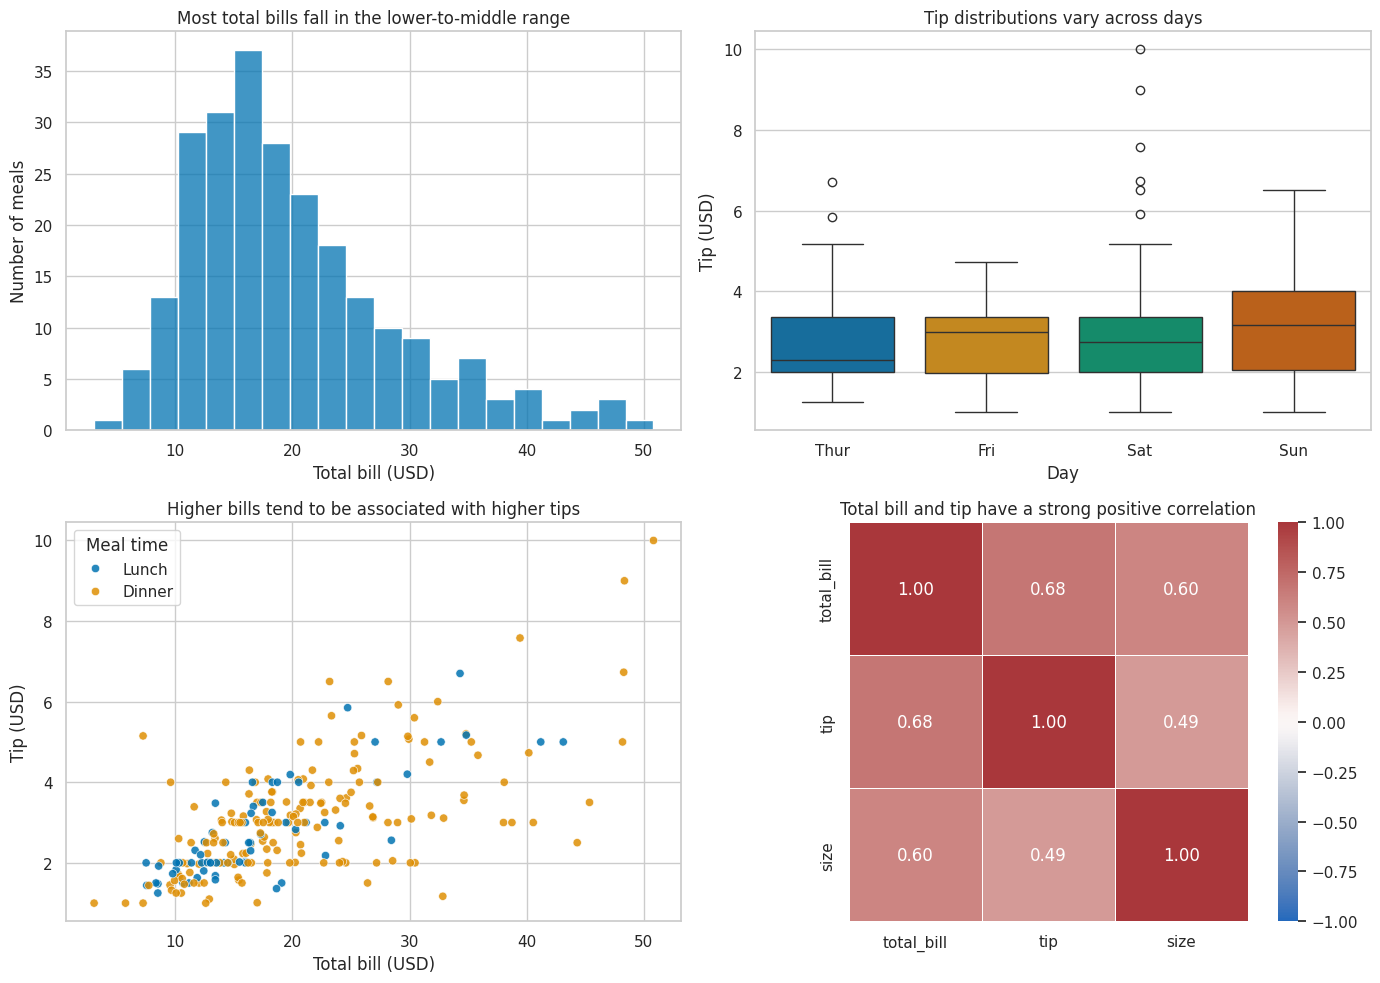

Saved dashboard image to: tips_visualization_dashboard.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Histogram of total bills
sns.histplot(
    data=tips, x="total_bill", bins=20,
    color=sns.color_palette("colorblind")[0],
    edgecolor="white", ax=axes[0, 0]
)
axes[0, 0].set(
    title="Most total bills fall in the lower-to-middle range",
    xlabel="Total bill (USD)",
    ylabel="Number of meals"
)

# Chart 2: Box plot of tips by day
sns.boxplot(
    data=tips, x="day", y="tip",
    hue="day", palette="colorblind",
    legend=False, ax=axes[0, 1]
)
axes[0, 1].set(
    title="Tip distributions vary across days",
    xlabel="Day",
    ylabel="Tip (USD)"
)

# Chart 3: Scatter plot of total bill versus tip
sns.scatterplot(
    data=tips, x="total_bill", y="tip",
    hue="time", palette="colorblind",
    alpha=0.85, ax=axes[1, 0]
)
axes[1, 0].set(
    title="Higher bills tend to be associated with higher tips",
    xlabel="Total bill (USD)",
    ylabel="Tip (USD)"
)
axes[1, 0].legend(title="Meal time")

# Chart 4: Correlation heatmap
numeric_corr = tips.select_dtypes(include="number").corr()
sns.heatmap(
    numeric_corr, annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, ax=axes[1, 1]
)
axes[1, 1].set_title("Total bill and tip have a strong positive correlation")

plt.tight_layout()
dashboard_path = "tips_visualization_dashboard.png"
plt.savefig(dashboard_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved dashboard image to: {dashboard_path}")

## 4. Generate evidence-based takeaways
This cell calculates the key statistics from the loaded data. Use these results in your written submission rather than guessing values.

In [ ]:
# 1. Bill distribution
bill_median = tips["total_bill"].median()
bill_q1 = tips["total_bill"].quantile(0.25)
bill_q3 = tips["total_bill"].quantile(0.75)
print(
    f"1. Bill distribution: the median total bill is ${bill_median:.2f}; "
    f"the middle 50% range from ${bill_q1:.2f} to ${bill_q3:.2f}."
)

# 2. Tip distributions by day: compare medians and sample counts
tip_by_day = tips.groupby("day", observed=True)["tip"].agg(["median", "mean", "count"]).sort_values("median", ascending=False)
display(tip_by_day.round(2))
top_day = tip_by_day["median"].idxmax()
print(
    f"2. Tips by day: {top_day} has the highest median tip "
    f"(${tip_by_day.loc[top_day, 'median']:.2f}) in this dataset."
)

# 3. Bill-tip association
bill_tip_corr = tips["total_bill"].corr(tips["tip"])
print(
    f"3. Bill and tip: the Pearson correlation is {bill_tip_corr:.2f}, "
    "indicating a positive association." if bill_tip_corr > 0 else
    f"3. Bill and tip: the Pearson correlation is {bill_tip_corr:.2f}."
)

# 4. Strongest off-diagonal numeric correlation
corr = tips.select_dtypes(include="number").corr()
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest_pair = corr_pairs.abs().idxmax()
strongest_value = corr_pairs.loc[strongest_pair]
print(
    f"4. Strongest numeric correlation: {strongest_pair[0]} and {strongest_pair[1]} "
    f"(r = {strongest_value:.2f})."
)

1. Bill distribution: the median total bill is $17.80; the middle 50% range from $13.35 to $24.13.


,median,mean,count
day,,,
Sun,3.15,3.26,76
Fri,3.00,2.73,19
Sat,2.75,2.99,87
Thur,2.30,2.77,62


2. Tips by day: Sun has the highest median tip ($3.15) in this dataset.
3. Bill and tip: the Pearson correlation is 0.68, indicating a positive association.
4. Strongest numeric correlation: total_bill and tip (r = 0.68).


## 5. Submission checklist
- [ ] Four questions are listed at the beginning.
- [ ] Histogram, box plot, scatter plot, and annotated correlation heatmap are included.
- [ ] Each chart has a clear title, labelled axes, and units.
- [ ] Colours are consistent and colour-blind-friendly.
- [ ] A one-line takeaway is provided for each chart.
- [ ] The dashboard image is saved at 150 dpi.
- [ ] Restart the runtime and run all cells from top to bottom.
- [ ] Upload the notebook, `tips_visualization_dashboard.png`, and written takeaways to GitHub or another shareable location.

**Interpretation note:** The charts show patterns and associations in the Tips dataset. They do not establish that one variable causes another.
